# Software Engineering for ML — From Notebook to Production

A Jupyter notebook is a scratchpad. Production code is a system.

The same model that achieves 94% accuracy in a notebook can fail silently in production because:
- There are no tests to catch regressions
- Configuration is hardcoded so different environments break
- Errors are unhandled so the service crashes under bad input
- There is no logging so debugging takes days instead of minutes
- There is no CI/CD so deploying takes a week of manual steps

This notebook is about the **mindset shift** from data scientist to ML engineer.

/tmp/ipykernel_188840/1722350356.py:49: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_188840/1722350356.py:49: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
.../site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
.../site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


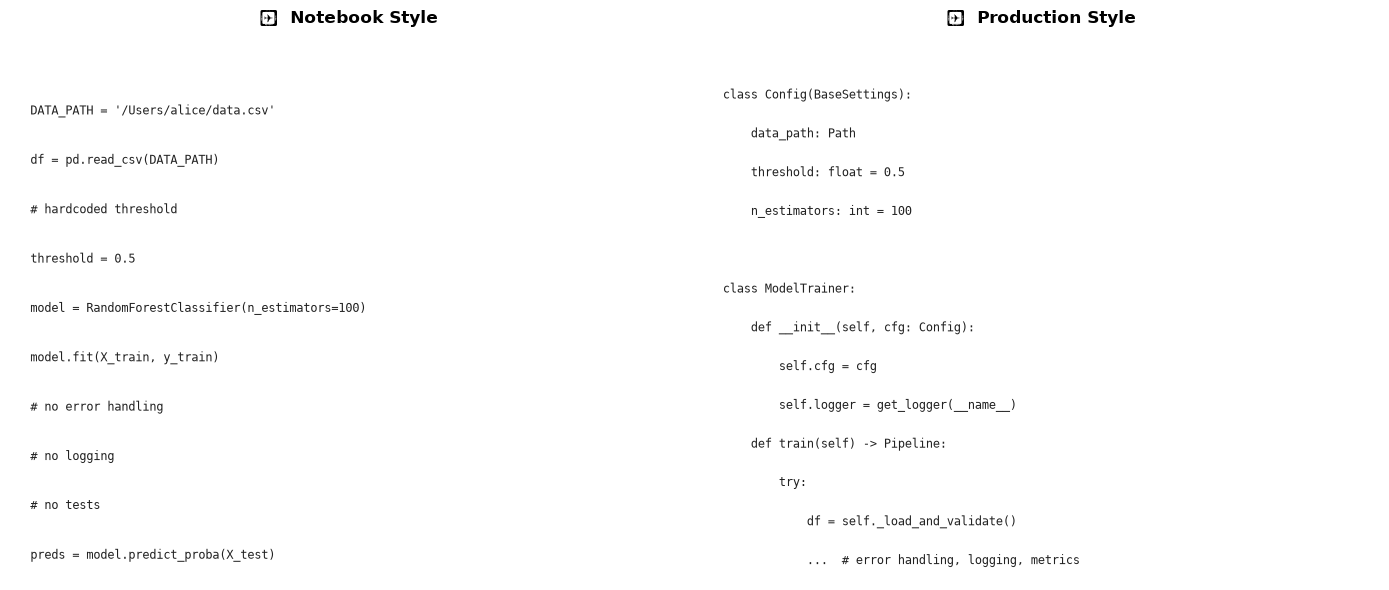

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ── Notebook vs Production Code Comparison ────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

notebook_code = [
    "DATA_PATH = '/Users/alice/data.csv'",
    "df = pd.read_csv(DATA_PATH)",
    "# hardcoded threshold",
    "threshold = 0.5",
    "model = RandomForestClassifier(n_estimators=100)",
    "model.fit(X_train, y_train)",
    "# no error handling",
    "# no logging",
    "# no tests",
    "preds = model.predict_proba(X_test)",
]

prod_code = [
    "class Config(BaseSettings):",
    "    data_path: Path",
    "    threshold: float = 0.5",
    "    n_estimators: int = 100",
    "",
    "class ModelTrainer:",
    "    def __init__(self, cfg: Config):",
    "        self.cfg = cfg",
    "        self.logger = get_logger(__name__)",
    "    def train(self) -> Pipeline:",
    "        try:",
    "            df = self._load_and_validate()",
    "            ...  # error handling, logging, metrics",
]

for ax, title, lines, color in [
    (ax1, '❌  Notebook Style', notebook_code, '#FFEBEE'),
    (ax2, '✅  Production Style', prod_code, '#E8F5E9'),
]:
    ax.set_facecolor(color)
    ax.set_xlim(0, 1); ax.set_ylim(0, len(lines) + 1)
    ax.axis('off')
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    for i, line in enumerate(reversed(lines)):
        ax.text(0.03, i + 0.5, line, fontsize=8.5, family='monospace',
                va='center', color='#212121')

plt.tight_layout()
plt.show()

## 1. Refactoring Notebook Code to Production Code

The logic stays identical. The structure changes completely.

In [2]:
import logging
import time
from dataclasses import dataclass, field
from pathlib import Path
from typing import Tuple
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# ── Config ────────────────────────────────────────────────────────────────────
@dataclass
class TrainingConfig:
    n_estimators: int = 100
    max_depth: int = 6
    test_size: float = 0.2
    random_seed: int = 42
    min_auc_threshold: float = 0.75   # gate: don't register if below this

# ── Structured logging ────────────────────────────────────────────────────────
logging.basicConfig(
    level=logging.INFO,
    format='{"time": "%(asctime)s", "level": "%(levelname)s", "msg": "%(message)s"}'
)
log = logging.getLogger('model_trainer')

# ── Trainer class ─────────────────────────────────────────────────────────────
class ModelTrainer:
    def __init__(self, cfg: TrainingConfig):
        self.cfg = cfg

    def load_data(self) -> Tuple[np.ndarray, np.ndarray]:
        log.info("Loading dataset")
        X, y = make_classification(n_samples=5000, n_features=20,
                                    n_informative=10, random_state=self.cfg.random_seed)
        log.info(f"Dataset: {X.shape[0]} rows, {X.shape[1]} features, "
                 f"class balance={y.mean():.2%}")
        return X, y

    def train(self) -> Pipeline:
        start = time.perf_counter()
        X, y = self.load_data()
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=self.cfg.test_size, random_state=self.cfg.random_seed
        )

        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('clf', RandomForestClassifier(
                n_estimators=self.cfg.n_estimators,
                max_depth=self.cfg.max_depth,
                random_state=self.cfg.random_seed,
                n_jobs=-1
            ))
        ])
        pipeline.fit(X_train, y_train)

        auc = roc_auc_score(y_test, pipeline.predict_proba(X_test)[:, 1])
        elapsed = time.perf_counter() - start

        log.info(f"Training complete: AUC={auc:.4f}, time={elapsed:.2f}s")

        if auc < self.cfg.min_auc_threshold:
            raise ValueError(f"AUC {auc:.4f} below threshold {self.cfg.min_auc_threshold}")

        return pipeline

# ── Run ───────────────────────────────────────────────────────────────────────
cfg = TrainingConfig(n_estimators=50)  # fast for demo
trainer = ModelTrainer(cfg)
model = trainer.train()
print(f"\nModel type: {type(model.named_steps['clf']).__name__}")
print("Production-quality trainer: config-driven, logged, gated by metric threshold.")

{"time": "2026-06-29 17:44:18,217", "level": "INFO", "msg": "Loading dataset"}


{"time": "2026-06-29 17:44:18,223", "level": "INFO", "msg": "Dataset: 5000 rows, 20 features, class balance=50.04%"}


{"time": "2026-06-29 17:44:18,397", "level": "INFO", "msg": "Training complete: AUC=0.9720, time=0.18s"}



Model type: RandomForestClassifier
Production-quality trainer: config-driven, logged, gated by metric threshold.


## 2. Project Structure for ML

A standard layout that separates concerns — notebooks for exploration, `src/` for production code, tests separate from implementation.

In [3]:
import os

structure = """
ml-project/
├── src/
│   ├── data/
│   │   ├── loader.py          # data ingestion, validation
│   │   └── preprocessing.py   # cleaning, transforms
│   ├── features/
│   │   └── engineering.py     # feature pipelines
│   ├── models/
│   │   ├── trainer.py         # training logic
│   │   └── evaluator.py       # metrics, reports
│   └── serving/
│       ├── api.py             # FastAPI app
│       └── predictor.py       # inference class
├── tests/
│   ├── unit/                  # fast, no I/O
│   └── integration/           # full pipeline
├── configs/
│   ├── training.yaml
│   └── serving.yaml
├── notebooks/                 # exploration only — never imported by src/
├── Dockerfile
├── requirements.txt
└── Makefile                   # make train / make test / make deploy
"""
print(structure)
print("Key rule: notebooks/ never imports from src/. src/ never imports from notebooks/.")
print("Notebooks are for exploration. src/ is for production. They are different worlds.")


ml-project/
├── src/
│   ├── data/
│   │   ├── loader.py          # data ingestion, validation
│   │   └── preprocessing.py   # cleaning, transforms
│   ├── features/
│   │   └── engineering.py     # feature pipelines
│   ├── models/
│   │   ├── trainer.py         # training logic
│   │   └── evaluator.py       # metrics, reports
│   └── serving/
│       ├── api.py             # FastAPI app
│       └── predictor.py       # inference class
├── tests/
│   ├── unit/                  # fast, no I/O
│   └── integration/           # full pipeline
├── configs/
│   ├── training.yaml
│   └── serving.yaml
├── notebooks/                 # exploration only — never imported by src/
├── Dockerfile
├── requirements.txt
└── Makefile                   # make train / make test / make deploy

Key rule: notebooks/ never imports from src/. src/ never imports from notebooks/.
Notebooks are for exploration. src/ is for production. They are different worlds.


## 3. Testing for ML — Three Levels

| Level | What It Tests | Speed | Tools |
|-------|--------------|-------|-------|
| **Unit** | Individual functions (deterministic) | <1s | pytest |
| **Integration** | Full pipeline end-to-end | 10–60s | pytest + fixtures |
| **Model** | Output shape, range, NaN, latency SLA | 1–10s | pytest |

The key insight: ML tests are not just about correctness — they are about **contracts**. A prediction must always be between 0 and 1. Latency must always be under 100ms. These are SLAs, and breaking them is a production incident.

In [4]:
import time
import numpy as np

# ── Model Contract Tests (what you'd put in tests/model/test_predictor.py) ───
def run_model_contract_tests(model, X_test: np.ndarray):
    results = []

    # Test 1: Output shape
    preds = model.predict_proba(X_test[:10])[:, 1]
    assert preds.shape == (10,), f"Expected (10,), got {preds.shape}"
    results.append(('Output shape', 'PASS'))

    # Test 2: Output range [0, 1]
    assert preds.min() >= 0.0 and preds.max() <= 1.0, \
        f"Scores out of range: [{preds.min():.3f}, {preds.max():.3f}]"
    results.append(('Output range [0,1]', 'PASS'))

    # Test 3: No NaN
    assert not np.isnan(preds).any(), "NaN in predictions"
    results.append(('No NaN in output', 'PASS'))

    # Test 4: Latency SLA < 100ms for single prediction
    t0 = time.perf_counter()
    _ = model.predict_proba(X_test[:1])
    latency_ms = (time.perf_counter() - t0) * 1000
    assert latency_ms < 100, f"Latency SLA breach: {latency_ms:.1f}ms > 100ms"
    results.append((f'Latency SLA <100ms ({latency_ms:.1f}ms)', 'PASS'))

    # Test 5: Deterministic (same input → same output, tolerance for float precision)
    pred_a = model.predict_proba(X_test[:1])[0, 1]
    pred_b = model.predict_proba(X_test[:1])[0, 1]
    assert np.isclose(pred_a, pred_b, rtol=1e-5), \
        f"Non-deterministic: {pred_a:.6f} vs {pred_b:.6f}"
    results.append(('Deterministic output', 'PASS'))

    return results

# Generate test data matching training distribution
X_test_data, _ = make_classification(n_samples=100, n_features=20,
                                      n_informative=10, random_state=99)
results = run_model_contract_tests(model, X_test_data)
print("=== Model Contract Test Results ===")
for test_name, status in results:
    print(f"  {'✅' if status == 'PASS' else '❌'} {test_name}: {status}")

=== Model Contract Test Results ===
  ✅ Output shape: PASS
  ✅ Output range [0,1]: PASS
  ✅ No NaN in output: PASS
  ✅ Latency SLA <100ms (12.4ms): PASS
  ✅ Deterministic output: PASS


## 4. CI/CD Pipeline for ML

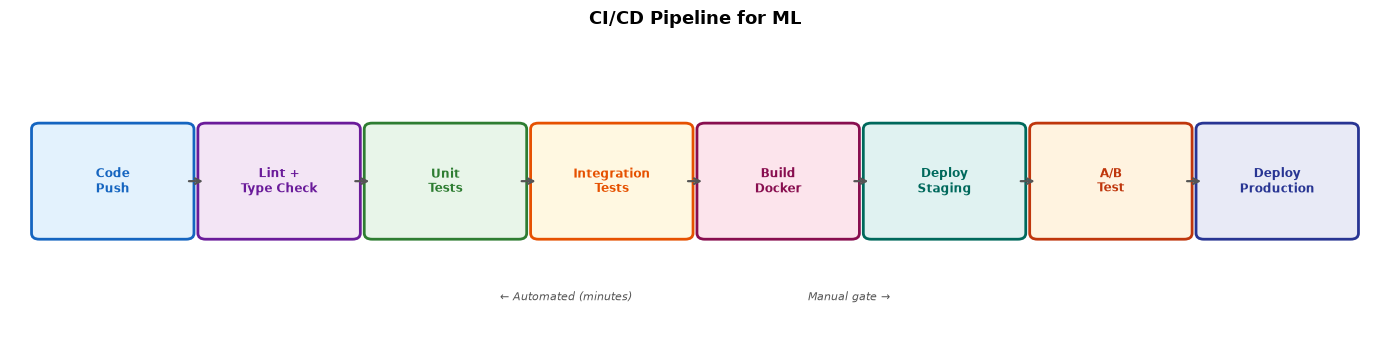

In [5]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.set_xlim(0, 14); ax.set_ylim(0, 4); ax.axis('off')
ax.set_title('CI/CD Pipeline for ML', fontsize=13, fontweight='bold')

steps = [
    (0.3,  '#E3F2FD', '#1565C0', 'Code\nPush'),
    (2.0,  '#F3E5F5', '#6A1B9A', 'Lint +\nType Check'),
    (3.7,  '#E8F5E9', '#2E7D32', 'Unit\nTests'),
    (5.4,  '#FFF8E1', '#E65100', 'Integration\nTests'),
    (7.1,  '#FCE4EC', '#880E4F', 'Build\nDocker'),
    (8.8,  '#E0F2F1', '#00695C', 'Deploy\nStaging'),
    (10.5, '#FFF3E0', '#BF360C', 'A/B\nTest'),
    (12.2, '#E8EAF6', '#283593', 'Deploy\nProduction'),
]

for x, fc, ec, label in steps:
    rect = mpatches.FancyBboxPatch((x, 1.3), 1.5, 1.4,
                                    boxstyle='round,pad=0.08', facecolor=fc, edgecolor=ec, lw=2)
    ax.add_patch(rect)
    ax.text(x + 0.75, 2.0, label, ha='center', va='center', fontsize=8.5,
            fontweight='bold', color=ec)

for i in range(len(steps) - 1):
    x = steps[i][0] + 1.5
    ax.annotate('', xy=(steps[i+1][0], 2.0), xytext=(x, 2.0),
                arrowprops=dict(arrowstyle='->', color='#555', lw=1.6))

ax.text(7.0, 0.4,
    '← Automated (minutes)                                            Manual gate →',
    ha='center', fontsize=8, color='#555', style='italic')
plt.tight_layout()
plt.show()

## 5. Containerization — Why Docker

**The problem Docker solves:** "It works on my machine." Python version, CUDA version, library versions all differ across laptops, staging servers, and production clusters. Docker packages the environment with the code.

```dockerfile
# Dockerfile for an ML model server
FROM python:3.11-slim

WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

COPY src/ src/
COPY models/ models/

EXPOSE 8000
CMD ["uvicorn", "src.serving.api:app", "--host", "0.0.0.0", "--port", "8000"]
```

```bash
docker build -t churn-model:v3.2 .
docker run -p 8000:8000 churn-model:v3.2
curl -X POST http://localhost:8000/predict -d '{"user_id": "u001", "features": {...}}'
```

**Key practices:**
- Pin exact versions in `requirements.txt` (`scikit-learn==1.9.0`, not `scikit-learn>=1.0`)
- Use `python:3.11-slim` not `python:3.11` — 200MB vs 900MB image size
- Never bake secrets into the image — use environment variables at runtime

## 6. Structured Logging

In [6]:
import json
import logging
import time
import uuid

class JSONFormatter(logging.Formatter):
    """Emit logs as JSON — machine-readable and searchable in Datadog/CloudWatch."""
    def format(self, record):
        return json.dumps({
            'timestamp': self.formatTime(record),
            'level': record.levelname,
            'message': record.getMessage(),
            **getattr(record, 'extra', {})
        })

def get_logger(name: str) -> logging.Logger:
    logger = logging.getLogger(name)
    handler = logging.StreamHandler()
    handler.setFormatter(JSONFormatter())
    logger.handlers = [handler]
    logger.setLevel(logging.INFO)
    return logger

def log_prediction(logger, user_id: str, model_version: str,
                   prediction: float, latency_ms: float):
    """Log a prediction event with all fields needed for debugging and monitoring."""
    record = logging.LogRecord(
        name='predictor', level=logging.INFO,
        pathname='', lineno=0,
        msg='prediction_served', args=(), exc_info=None
    )
    record.extra = {
        'request_id': str(uuid.uuid4())[:8],
        'user_id': user_id,
        'model_version': model_version,
        'prediction': round(prediction, 4),
        'latency_ms': round(latency_ms, 2),
        # Never log: raw features (PII risk), full input vectors (storage cost)
    }
    logger.handle(record)

logger = get_logger('predictor')
print("=== Structured Log Output ===")
for uid, pred in [('u001', 0.87), ('u002', 0.12), ('u003', 0.61)]:
    log_prediction(logger, uid, 'churn-v3.2', pred, np.random.uniform(10, 40))

{"timestamp": "2026-06-29 17:44:18,794", "level": "INFO", "message": "prediction_served", "request_id": "5f14afb1", "user_id": "u001", "model_version": "churn-v3.2", "prediction": 0.87, "latency_ms": 30.38}


{"time": "2026-06-29 17:44:18,794", "level": "INFO", "msg": "prediction_served"}


{"timestamp": "2026-06-29 17:44:18,795", "level": "INFO", "message": "prediction_served", "request_id": "aa78dcd5", "user_id": "u002", "model_version": "churn-v3.2", "prediction": 0.12, "latency_ms": 25.05}


{"time": "2026-06-29 17:44:18,795", "level": "INFO", "msg": "prediction_served"}


{"timestamp": "2026-06-29 17:44:18,796", "level": "INFO", "message": "prediction_served", "request_id": "202fc032", "user_id": "u003", "model_version": "churn-v3.2", "prediction": 0.61, "latency_ms": 33.86}


{"time": "2026-06-29 17:44:18,796", "level": "INFO", "msg": "prediction_served"}


=== Structured Log Output ===


## 7. The ML Engineer Toolkit

| Category | Tool | Why You Need It |
|----------|------|----------------|
| **Experiment tracking** | MLflow, Weights & Biases | Reproducibility — know exactly what produced each model |
| **Orchestration** | Airflow, Prefect, Dagster | Schedule and monitor training pipelines |
| **Serving** | FastAPI, TorchServe, Triton | Get predictions to users reliably |
| **Monitoring** | Evidently, WhyLabs, Arize | Detect drift and degradation before users do |
| **Containerization** | Docker, Kubernetes | Run anywhere, scale automatically |
| **Feature Store** | Feast, Tecton, Hopsworks | Eliminate training-serving skew |
| **CI/CD** | GitHub Actions, Jenkins | Automate testing and deployment |
| **Data versioning** | DVC, Delta Lake | Reproduce any past training run |

## Key Takeaways

1. **Structure beats cleverness** — a boring, well-structured codebase outlasts a clever notebook by years
2. **Config everything** — if it might change between environments, it belongs in config, not code
3. **Test the contract, not just the logic** — output shape, range, latency are as important as accuracy
4. **Log everything you would want during an incident** — you will thank yourself at 3am
5. **Containerize early** — "works on my machine" is not a deployment strategy

## Additional Learning Resources
- **Designing Machine Learning Systems** — Chip Huyen (O'Reilly, 2022) — the definitive ML engineering book
- **Designing Data-Intensive Applications** — Martin Kleppmann — systems thinking applied to data
- **Machine Learning Engineering** — Andriy Burkov — practical ML in production
- **Made With ML** — madewithml.com — free MLOps course, highly recommended
- **Full Stack Deep Learning** — fullstackdeeplearning.com — lectures + labs
- **System Design Interview Vol 1 & 2** — Alex Xu — for ML system design interviews
- **The Pragmatic Programmer** — Hunt & Thomas — software engineering fundamentals that never go stale